# CHILLED - Chiller Health Indicator Learning & Early Detection

In [27]:
import polars as pl
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [28]:
df = pl.read_csv('output/chiller_data.csv')
print(df.shape)
print(df.schema)
root_df = df

(2508, 46)
Schema({'date': String, 'chiller_id': String, 'timestamp': String, 'refrigerant_leak_status': String, 'opening_of_vane': Float64, 'opening_hot_gas_bypass_valve': Float64, 'opening_of_2nd_vane': Float64, 'opening_of_high_stage_expansion_valve': Float64, 'opening_of_low_stage_expansion_valve': Float64, 'motor_voltage': Float64, 'motor_current': Float64, 'motor_input': Float64, 'compressor_running_time': Float64, 'compressor_suction_temperature': String, 'compressor_discharge_temperature': String, 'compressor_oil_tank_oil_temperature': Float64, 'compressor_oil_pressure': Float64, 'compressor_oil_level': String, 'compressor_oil_supply_temperature': Float64, 'evaporator_evaporating_pressure': Float64, 'evaporator_evaporating_temperature': Float64, 'evaporator_saturation_temperature': Float64, 'evaporator_approach_temp': Float64, 'evaporator_chilled_water_flow_rate': Float64, 'evaporator_chilled_water_entering_temperature': Float64, 'evaporator_chilled_water_leaving_temperature': 

In [29]:
pl.Config.set_tbl_rows(20)
df.head(15)

date,chiller_id,timestamp,refrigerant_leak_status,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_suction_temperature,compressor_discharge_temperature,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_level,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_liquid_level_side_glass_bottom,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,heat_balance,cop,pct_of_cooling_capacity,pct_of_motor_input,evaporator_metric_24
str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,str,str,str
"""2024-06-05""","""EC0120A""","""00:00""",null,70.5,0.0,64.3,64.4,55.8,6.6,116.5,1139.0,45688.6,null,null,57.9,5.2,null,45.2,0.23,4.2,3.9,0.5,696.3,13.3,4.7,8.6,6914.757506,0.83,36.6,37.0,2.0,null,29.4,35.0,5.6,1225.3,7923.418014,0.47,20.3,203.8,null,5.52,null,null,null
"""2024-06-05""","""EC0120A""","""09:00""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,null,null,1225.3,0.0,null,null,null,null,null,null,null,null
"""2024-06-05""","""EC0120B""","""00:00""",null,81.8,0.0,77.6,65.6,50.4,6.6,119.4,1212.0,46429.2,null,null,59.2,0.49,null,45.0,0.21,3.3,2.5,1.4,668.1,13.3,4.7,8.6,6634.711316,0.87,37.5,38.4,4.3,null,29.2,34.1,4.9,1264.7,7155.923788,0.47,19.8,121.3,null,5.23,null,null,null
"""2024-06-05""","""EC0120B""","""09:00""",null,77.7,0.0,75.4,65.9,46.9,6.6,117.4,1206.0,46437.0,null,null,59.2,4.49,null,45.0,0.22,3.9,2.8,1.1,712.0,12.7,5.0,7.7,6330.715935,0.87,37.9,38.6,4.1,null,29.4,34.5,5.1,1286.0,7573.441109,0.47,20.3,136.2,null,4.76,null,null,null
"""2024-06-05""","""EC0120C""","""00:00""",null,74.4,0.0,68.8,62.6,39.2,6.6,117.7,1209.0,44231.8,null,null,58.0,0.59,null,44.7,0.23,4.7,3.7,-0.3,661.2,13.2,4.4,8.8,6718.891455,0.85,36.9,37.5,2.6,null,29.3,34.9,5.6,1294.0,8367.667436,0.46,19.8,197.3,null,5.33,null,null,null
"""2024-06-05""","""EC0120C""","""09:00""",null,71.2,0.0,67.6,62.6,37.1,6.6,115.2,1191.0,44240.0,null,null,58.2,0.59,null,45.1,0.23,4.8,3.9,-0.3,702.0,12.7,4.5,8.2,6647.113164,0.85,37.1,37.8,2.7,null,29.6,35.1,5.5,1297.0,8237.297921,0.47,20.1,203.2,null,5.08,null,null,null
"""2024-06-05""","""EC0120D""","""00:00""",null,73.5,0.1,68.1,64.9,35.2,6.6,118.6,1212.0,46445.0,null,null,57.5,0.54,null,44.7,0.23,4.7,3.6,0.3,701.4,13.2,5.0,8.2,6641.431871,0.86,38.0,38.3,3.4,null,29.2,34.9,5.7,1198.0,7885.2194,0.48,21.0,205.9,null,4.98,null,null,null
"""2024-06-05""","""EC0120D""","""09:00""",null,73.5,0.1,67.9,65.3,32.8,6.6,118.8,1215.0,46453.0,null,null,57.5,0.54,null,44.9,0.23,4.8,3.7,0.3,748.0,12.8,5.1,7.7,6650.808314,0.87,38.2,38.4,3.3,null,29.5,35.1,5.6,1220.0,7889.145497,0.49,21.2,217.4,null,4.68,null,null,null
"""2024-06-05""","""EC0120E""","""00:00""",null,null,null,null,null,null,6.6,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,null,0.0,null,0.0,null,null,null,null,null,null,null,null


In [30]:
df.describe()

statistic,date,chiller_id,timestamp,refrigerant_leak_status,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_suction_temperature,compressor_discharge_temperature,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_level,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_liquid_level_side_glass_bottom,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,heat_balance,cop,pct_of_cooling_capacity,pct_of_motor_input,evaporator_metric_24
str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,str,str,str
"""count""","""2508""","""2508""","""2508""","""1839""",1607.0,1607.0,1607.0,1607.0,1604.0,1671.0,1607.0,1607.0,1559.0,"""0""","""0""",1607.0,1605.0,"""2""",1605.0,1606.0,1604.0,1604.0,2459.0,1606.0,1606.0,1606.0,2471.0,2460.0,1606.0,1604.0,1605.0,2481.0,"""1""",1606.0,1606.0,2475.0,1607.0,2485.0,1606.0,1605.0,1606.0,"""0""",1606.0,"""2""","""0""","""24"""
"""null_count""","""0""","""0""","""0""","""669""",901.0,901.0,901.0,901.0,904.0,837.0,901.0,901.0,949.0,"""2508""","""2508""",901.0,903.0,"""2506""",903.0,902.0,904.0,904.0,49.0,902.0,902.0,902.0,37.0,48.0,902.0,904.0,903.0,27.0,"""2507""",902.0,902.0,33.0,901.0,23.0,902.0,903.0,902.0,"""2508""",902.0,"""2506""","""2508""","""2484"""
"""mean""",null,null,null,null,74.437772,0.140261,69.383199,69.491867,44.669264,7.020766,117.372222,1180.489172,49955.419949,null,null,58.207716,0.554841,null,44.996573,0.227634,4.126496,3.298211,0.946795,660.480679,13.302677,4.830822,5.500364,4143.824946,0.876164,36.109121,36.623925,1.796372,null,28.541968,33.894085,3.465737,1258.417554,4999.1552,0.519875,19.809875,184.104134,null,5.4784,null,null,null
"""std""",null,null,null,null,3.373344,1.808525,4.76401,29.138334,10.998752,14.773625,4.965425,49.425639,24490.42669,null,null,1.677108,1.22032,null,1.600992,0.053015,0.465814,1.075358,10.137757,33.363716,2.976027,12.520819,11.118173,9164.744913,2.00961,1.200236,2.078188,2.246753,null,0.936305,1.056961,2.701266,71.83696,3925.033645,1.641825,4.496737,55.880966,null,0.282415,null,null,null
"""min""","""2024-06-05""","""EC0120A""","""00:00""","""2028-11-12 09:36:00""",36.6,0.0,27.4,6.8,2.7,6.6,81.5,12.3,3179.0,null,null,44.5,0.43,"""m""",4.5,0.2,2.1,0.23,-13.8,375.2,9.8,3.5,-492.1,-412488.903002,0.0,0.83,2.7,-34.6,""" """,26.6,4.1,-24.6,129.1,-36762.512702,0.24,17.6,2.87,null,4.54,"""5.75""",null,"""0"""
"""25%""",null,null,null,null,72.4,0.0,67.5,65.0,37.3,6.6,116.1,1169.0,46861.0,null,null,57.7,0.49,null,44.9,0.22,3.9,2.9,0.0,637.8,13.0,4.2,0.0,0.0,0.81,35.6,36.2,0.0,null,28.0,33.4,0.0,1239.4,0.0,0.46,19.3,159.8,null,5.3,null,null,null
"""50%""",null,null,null,null,74.3,0.0,69.4,68.1,41.9,6.6,117.2,1187.0,49332.2,null,null,58.4,0.52,null,45.0,0.22,4.2,3.3,0.8,648.6,13.3,4.5,8.4,6458.752887,0.82,36.2,36.7,2.2,null,28.6,33.9,5.1,1292.5,7518.12933,0.46,19.7,198.6,null,5.52,null,null,null
"""75%""",null,null,null,null,76.4,0.1,71.9,71.7,51.7,6.6,118.3,1200.0,50798.7,null,null,59.0,0.53,null,45.1,0.23,4.4,3.6,1.2,677.92,13.5,4.8,8.9,6697.30254,0.84,36.7,37.3,2.9,null,29.0,34.4,5.

The columns that are almost only null values are droped entirely

In [31]:
all_null_cols = [
    'compressor_suction_temperature',
    'compressor_discharge_temperature',
    'compressor_oil_level',
    'condensor_liquid_level_side_glass_bottom',
    'heat_balance',
    'pct_of_cooling_capacity',
    'pct_of_motor_input',
    'evaporator_metric_24'
]

df = df.drop(all_null_cols)

## Formatting

For easier handling, some columns are transformed

- timestamps: instead of two columns for data and time, only one timestamp column
- chiller_id: the last letter of the string is enough to identify the chiller unit
- refrigerant_leak_status: instead of "OK" string, column is translated to 0 and 1

In [32]:
df = df.with_columns(
    (pl.col('date') + " " + pl.col('timestamp'))
    .str.to_datetime("%Y-%m-%d %H:%M")
    .alias("timestamp")
)

df = df.drop('date')

In [33]:
df["chiller_id"].value_counts()

# Verifies that all measurements translate to only 6 units, only use the last letter for identification

chiller_id,count
str,u32
"""EC0120E""",418
"""EC0120A""",418
"""EC0120D""",418
"""EC0120F""",418
"""EC0120C""",418
"""EC0120B""",418


In [34]:
df = df.with_columns(
    pl.col('chiller_id').str.tail(1)
)

In [35]:
df = df.with_columns(
    pl.when(pl.col('refrigerant_leak_status') == "OK")
        .then(1)
        .otherwise(0)
        .alias('is_refrigerant_leak_healthy (bool)')
)

df = df.drop('refrigerant_leak_status')

In [36]:
df.head()

chiller_id,timestamp,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
str,datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32
"""A""",2024-06-05 00:00:00,70.5,0.0,64.3,64.4,55.8,6.6,116.5,1139.0,45688.6,57.9,5.2,45.2,0.23,4.2,3.9,0.5,696.3,13.3,4.7,8.6,6914.757506,0.83,36.6,37.0,2.0,29.4,35.0,5.6,1225.3,7923.418014,0.47,20.3,203.8,5.52,0
"""A""",2024-06-05 09:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,null,1225.3,0.0,null,null,null,null,0
"""B""",2024-06-05 00:00:00,81.8,0.0,77.6,65.6,50.4,6.6,119.4,1212.0,46429.2,59.2,0.49,45.0,0.21,3.3,2.5,1.4,668.1,13.3,4.7,8.6,6634.711316,0.87,37.5,38.4,4.3,29.2,34.1,4.9,1264.7,7155.923788,0.47,19.8,121.3,5.23,0
"""B""",2024-06-05 09:00:00,77.7,0.0,75.4,65.9,46.9,6.6,117.4,1206.0,46437.0,59.2,4.49,45.0,0.22,3.9,2.8,1.1,712.0,12.7,5.0,7.7,6330.715935,0.87,37.9,38.6,4.1,29.4,34.5,5.1,1286.0,7573.441109,0.47,20.3,136.2,4.76,0
"""C""",2024-06-05 00:00:00,74.4,0.0,68.8,62.6,39.2,6.6,117.7,1209.0,44231.8,58.0,0.59,44.7,0.23,4.7,3.7,-0.3,661.2,13.2,4.4,8.8,6718.891455,0.85,36.9,37.5,2.6,29.3,34.9,5.6,1294.0,8367.667436,0.46,19.8,197.3,5.33,0


## Columns with approx 900 null values

The `df.head()` output showed, that there are quite a few rows that have approximately 900 null values. Let's further explore if these null values all ocur within the same rows, or if they are spread to different rows.

In [37]:
df.null_count()

chiller_id,timestamp,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,901,901,901,901,904,837,901,901,949,901,903,903,902,904,904,49,902,902,902,37,48,902,904,903,27,902,902,33,901,23,902,903,902,902,0


In [38]:
# Cols mostly affected by the many nulls issue

null_cols = [
    'opening_of_vane',
    'opening_hot_gas_bypass_valve',
    'opening_of_2nd_vane',
    'opening_of_high_stage_expansion_valve',
    'motor_current',
    'motor_input',
    'compressor_running_time',
    'compressor_oil_tank_oil_temperature',
    'compressor_oil_pressure',
    'compressor_oil_supply_temperature',
    'evaporator_evaporating_pressure',
    'evaporator_evaporating_temperature',
    'evaporator_saturation_temperature',
    'evaporator_chilled_water_flow_rate',
    'evaporator_chilled_water_entering_temperature',
    'evaporator_chilled_water_leaving_temperature',
    'condensor_condensing_pressure',
    'condensor_consensed_liquid_temperature',
    'condensor_saturated_temeprature',
    'condensor_cooling_water_entering_temperature',
    'condensor_cooling_water_leaving_temperature',
    'condensor_cooling_water_flow_rate',
    'economizer_economizer_pressure',
    'economizer_saturated_temperature',
    'economizer_liquid_level',
    'cop'
]

# Are the null masks identical across all these columns?
masks = df.select([pl.col(c).is_null().alias(c) for c in null_cols])

# rows where ALL are null vs rows where ANY is null
summary = df.select(
    n_all_null = pl.all_horizontal(pl.col(c).is_null() for c in null_cols).sum(),
    n_any_null = pl.any_horizontal(pl.col(c).is_null() for c in null_cols).sum(),
)
print(summary)

shape: (1, 2)
┌────────────┬────────────┐
│ n_all_null ┆ n_any_null │
│ ---        ┆ ---        │
│ u32        ┆ u32        │
╞════════════╪════════════╡
│ 894        ┆ 966        │
└────────────┴────────────┘


Many rows indeed have all null values in our specified columns. It seems like the null values at least are concentrated on the smallest possible number of rows (even though it's still a lot of rows). Let's further explore what the rows look like that have a lot of null values and if the rows might still carry insights. 

In [39]:
dup_df = df.drop(["timestamp", "chiller_id"])
dup_df = dup_df.filter(dup_df.is_duplicated())
dup_counts_df = dup_df.group_by(pl.all()).len().sort("len", descending=True)
dup_counts_df.select('len', pl.exclude('len'))

len,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32
485,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,0
224,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,1
45,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,1.0,null,null,0.0,null,0.0,null,null,null,null,0
41,null,null,null,null,null,6.6,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,0
21,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0
19,null,null,null,null,null,6.6,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,1
16,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,0
14,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,1.0,null,null,0.0,null,0.0,null,null,null,null,1
6,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,null,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,0


The vast majority of duplicate rows are the ones where the identified columns are null. Also when a row almost contains only null values, the entry doesn't carry enough information and is assumed to be an empty record actually. The rows with a lot of null values are for now added to a mask for later dropping.

In [40]:
null_mask = pl.all_horizontal(pl.col(c).is_null() for c in null_cols)

There are still a few cols that have a lot of null values

In [41]:
df.filter(~null_mask).describe()

statistic,chiller_id,timestamp,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""1614""","""1614""",1607.0,1607.0,1607.0,1607.0,1604.0,1606.0,1607.0,1607.0,1559.0,1607.0,1605.0,1605.0,1606.0,1604.0,1604.0,1609.0,1606.0,1606.0,1606.0,1612.0,1597.0,1606.0,1604.0,1605.0,1613.0,1606.0,1606.0,1611.0,1607.0,1614.0,1606.0,1605.0,1606.0,1606.0,1614.0
"""null_count""","""0""","""0""",7.0,7.0,7.0,7.0,10.0,8.0,7.0,7.0,55.0,7.0,9.0,9.0,8.0,10.0,10.0,5.0,8.0,8.0,8.0,2.0,17.0,8.0,10.0,9.0,1.0,8.0,8.0,3.0,7.0,0.0,8.0,9.0,8.0,8.0,0.0
"""mean""",null,"""2024-12-29 21:49:57.769516""",74.437772,0.140261,69.383199,69.491867,44.669264,7.037796,117.372222,1180.489172,49955.419949,58.207716,0.554841,44.996573,0.227634,4.126496,3.298211,1.446967,660.480679,13.302677,4.830822,8.43139,6383.099166,0.876164,36.109121,36.623925,2.725232,28.541968,33.894085,5.324457,1258.417554,7696.964481,0.519875,19.809875,184.104134,5.4784,0.975217
"""std""",null,null,3.373344,1.808525,4.76401,29.138334,10.998752,15.069563,4.965425,49.425639,24490.42669,1.677108,1.22032,1.600992,0.053015,0.465814,1.075358,12.505081,33.363716,2.976027,12.520819,12.83736,10728.798065,2.00961,1.200236,2.078188,2.294167,0.936305,1.056961,1.144481,71.83696,1716.701054,1.641825,4.496737,55.880966,0.282415,0.155512
"""min""","""A""","""2024-06-05 00:00:00""",36.6,0.0,27.4,6.8,2.7,6.6,81.5,12.3,3179.0,44.5,0.43,4.5,0.2,2.1,0.23,-13.8,375.2,9.8,3.5,-492.1,-412488.903002,0.0,0.83,2.7,-34.6,26.6,4.1,-24.6,129.1,-36762.512702,0.24,17.6,2.87,4.54,0.0
"""25%""",null,"""2024-07-25 09:00:00""",72.4,0.0,67.5,65.0,37.3,6.6,116.1,1169.0,46861.0,57.7,0.49,44.9,0.22,3.9,2.9,0.8,637.8,13.0,4.2,8.4,6473.152425,0.81,35.6,36.2,2.2,28.0,33.4,5.2,1239.4,7552.369515,0.46,19.3,159.8,5.3,1.0
"""50%""",null,"""2025-03-15 00:00:00""",74.3,0.0,69.4,68.1,41.9,6.6,117.2,1187.0,49332.2,58.4,0.52,45.0,0.22,4.2,3.3,1.1,648.6,13.3,4.5,8.8,6638.152425,0.82,36.2,36.7,2.6,28.6,33.9,5.4,1292.5,7885.450346,0.46,19.7,198.6,5.52,1.0
"""75%""",null,"""2025-05-11 00:00:00""",76.4,0.1,71.9,71.7,51.7,6.6,118.3,1200.0,50798.7,59.0,0.53,45.1,0.23,4.4,3.6,1.4,677.92,13.5,4.8,9.0,6788.048499,0.84,36.7,37.3,3.3,29.0,34.4,5.6,1297.8,8104.988453,0.47,20.1,205.6,5.67,1.0
"""max""","""F""","""2025-06-30 09:00:00""",83.9,72.2,81.0,739.0,100.0,606.0,196.9,1243.0,495779.0,62.4,49.0,59.6,2.2,5.5,36.5,501.9,768.8,131.3,506.0,126.7,94009.644342,81.0,38.8,63.2,31.9,39.5,36.5,7.9,1361.7,11527.431871,47.0,196.5,2000.8,6.32,1.0


Let's take a look at the null value count per row and check how many rows are still affected by the issue

In [42]:
n_nulls_df = df.filter(~null_mask).with_columns(
    pl.sum_horizontal(pl.all().is_null()).alias('n_nulls')
)


display(n_nulls_df.select("n_nulls", pl.exclude("n_nulls")).sort('n_nulls', descending=True).head(20))
display(n_nulls_df.select("n_nulls", pl.exclude("n_nulls")).sort('n_nulls', descending=True).group_by("n_nulls").len())



n_nulls,chiller_id,timestamp,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
u32,str,datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32
28,"""A""",2024-06-05 09:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,null,1225.3,0.0,null,null,null,null,0
28,"""A""",2024-07-23 00:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,5.28,1
27,"""A""",2024-07-24 00:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,5.28,0
27,"""D""",2025-04-03 09:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,5.11,1
27,"""D""",2025-04-22 09:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,1293.74,0.0,null,null,null,null,0
27,"""E""",2025-04-29 09:00:00,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,1246.0,0.0,null,null,null,null,0
17,"""A""",2025-03-14 00:00:00,70.6,0.1,64.7,67.4,36.2,6.6,117.2,1147.0,49077.0,58.5,0.53,null,null,null,null,0.3,null,null,null,8.4,6286.226328,null,null,null,2.6,null,null,5.9,null,7484.551963,null,null,null,null,1
17,"""B""",2025-05-02 00:00:00,77.3,0.0,72.1,68.8,54.7,6.6,114.7,1166.0,51293.0,59.1,0.49,null,null,null,null,0.0,null,null,null,0.0,0.0,null,null,null,0.0,null,null,0.0,null,0.0,null,null,null,null,1
11,"""B""",2025-03-14 09:00:00,null,null,null,null,null,null,null,null,null,null,null,44.7,0.22,4.2,3.2,2.1,646.7,13.7,5.5,8.3,6282.69746,0.83,36.1,36.9,4.1,28.3,33.4,4.8,1226.2,7206.540416,0.46,19.7,119.8,5.41,1


n_nulls,len
u32,u32
28,2
27,4
17,2
11,1
2,4
1,86
0,1515


There a few more rows with rather sparse data. We'll also drop the rwos that have more than 2 missing values, since it's not that many rows and there values don't seem out of the ordinary. Accordingly the null mask is adjusted.

In [43]:
null_mask = pl.sum_horizontal(pl.all().is_null()) > 2

Now before we drop those rows entirely we want to take a closer look at these rows to maybe identify a pattern.

In [44]:
df.filter(null_mask) \
  .select(["timestamp", "chiller_id"]) \
  .group_by("chiller_id") \
  .len() \
  .sort("chiller_id")

chiller_id,len
str,u32
"""A""",136
"""B""",159
"""C""",133
"""D""",133
"""E""",145
"""F""",197


It's not only one chiller unit that is affected by the null values. All of the units experience the same problems. Let's take a further look at which time of day the null values mostly appear

In [45]:
(
    df.filter(null_mask)
    .group_by(pl.col("timestamp").dt.time())
    .agg(pl.len().alias("count"))
    .with_columns(
        pct = pl.col("count") / pl.col("count").sum() * 100
    )
)

timestamp,count,pct
time,u32,f64
00:00:00,98,10.852713
09:00:00,805,89.147287


This is quite interesting: Almost 90% of null values are present at the 9am measurement cycle. Next, we'll take a look if the null values appear in specific time periods.

In [46]:
null_plt_df = (
    df.filter(null_mask)
    .group_by(pl.col("timestamp").dt.date().alias("date"), "chiller_id")
    .len()
)

# Full grid of all dates x all chiller_ids
all_dates = df.select(pl.col("timestamp").dt.date().alias("date")).unique()
all_chillers = df.select("chiller_id").unique()
full_grid = all_dates.join(all_chillers, how="cross")

null_plt_df = (
    full_grid
    .join(null_plt_df, on=["date", "chiller_id"], how="left")
    .with_columns(pl.col("len").fill_null(0))
    .sort("date")
)

px.line(
    null_plt_df,
    x="date", y="len",
    color="chiller_id"
)

Looking at this graph, we make a few observations:
- There are date, chiller combinations with 3 (!) null measurments per day. That should not possible since per day there's only two measurements. After further investigating the dataset, we can see that the date field was set to the same dates for a few sheets of xlxs files and also the values looked quite similar, but will further investigate that soon
- Zooming closer to the pattern of null counts per day per chiller, we can see a few days with 2 missing values, but the null measurments seem to be alternating between 0 and 1, meaning that most units are measured every second day and not on every day.  

In [47]:
null_plt_df = (
    df.filter(null_mask)
    .group_by(pl.col("timestamp").dt.date().alias("date"), pl.col("timestamp").dt.time().alias("time"), "chiller_id")
    .len()
)

# Full grid of all dates x all chiller_ids
all_dates = df.select(pl.col("timestamp").dt.date().alias("date")).unique()
all_chillers = df.select("chiller_id").unique()
all_times = df.select(pl.col("timestamp").dt.time().alias("time")).unique()
full_grid = all_dates.join(all_chillers, how="cross").join(all_times, how="cross")

null_plt_df = (
    full_grid
    .join(null_plt_df, on=["date", "time", "chiller_id"], how="left")
    .with_columns(pl.col("len").fill_null(0))
    .sort("date")
)

fig = px.line(
    null_plt_df,
    x="date", y="len",
    color="time", 
    facet_row="chiller_id",
    height=800
)

fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))

fig.show()

This is another interesting graph: It shows when there was no value recorded on a day for each chiller unit, across the inspected time period. We can make the following observations:
-  The zig-zag pattern we noticed earlier is caused by the measurements that take place at 9am. the measurements at 0:00 are really consistent have almost no null values
-  For the 0:00 measurements there are a few dates where null values have been recorded for all chillers. These are
   -  2025-03-08
   -  2025-03-16
   -  2025-03-24
   -  2025-04-09
   -  2025-04-17

We have to keep that in mind when we work on only one of the time groups and maybe should put more emphasis on the 0:00 measurement series since it's more complete

Next we'll take a closer look at the timestamp, chiller_id duplicates and see if they also have duplicate measurement values besides the same date

In [48]:
with pl.Config(tbl_rows= -1):
    display(
        df.filter(~null_mask)
        .filter(pl.col("chiller_id").len().over(["timestamp", "chiller_id"]) >= 2)
    )

chiller_id,timestamp,opening_of_vane,opening_hot_gas_bypass_valve,opening_of_2nd_vane,opening_of_high_stage_expansion_valve,opening_of_low_stage_expansion_valve,motor_voltage,motor_current,motor_input,compressor_running_time,compressor_oil_tank_oil_temperature,compressor_oil_pressure,compressor_oil_supply_temperature,evaporator_evaporating_pressure,evaporator_evaporating_temperature,evaporator_saturation_temperature,evaporator_approach_temp,evaporator_chilled_water_flow_rate,evaporator_chilled_water_entering_temperature,evaporator_chilled_water_leaving_temperature,evaporator_temperature_difference,evaporator_chilling_capacity,condensor_condensing_pressure,condensor_consensed_liquid_temperature,condensor_saturated_temeprature,condensor_approach_temp_cond_lq_temp_leaving_temp,condensor_cooling_water_entering_temperature,condensor_cooling_water_leaving_temperature,condensor_temperature_difference_cooling_water,condensor_cooling_water_flow_rate,condensor_heat_capacity,economizer_economizer_pressure,economizer_saturated_temperature,economizer_liquid_level,cop,is_refrigerant_leak_healthy (bool)
str,datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32
"""B""",2025-03-14 00:00:00,80.0,0.0,76.2,68.8,50.9,6.6,118.1,1194.0,50889.0,59.4,0.49,44.8,0.22,3.3,2.5,1.4,640.32,12.3,3.9,8.4,6210.95612,0.84,36.6,37.1,4.0,27.8,33.1,5.3,1163.82,7122.685912,0.46,19.5,122.6,5.36,1
"""B""",2025-03-14 00:00:00,80.0,0.0,76.2,68.8,50.9,6.6,118.1,1194.0,50747.0,59.4,0.49,44.8,0.22,3.3,2.5,1.4,640.32,12.3,3.9,8.4,6210.95612,0.84,36.6,37.1,4.0,27.8,33.1,5.3,1163.82,7122.685912,0.46,19.5,122.6,5.36,1
"""C""",2025-03-14 00:00:00,74.0,0.0,69.0,63.6,39.9,6.6,116.7,1181.0,48519.0,57.5,0.59,45.0,0.23,4.2,3.5,1.0,639.92,13.1,4.5,8.6,6354.863741,0.82,36.4,36.4,3.0,27.9,33.4,5.5,1186.5,7535.508083,0.46,19.7,202.2,5.66,1
"""C""",2025-03-14 00:00:00,74.0,0.0,69.0,63.6,39.9,6.6,116.7,1181.0,48404.0,57.5,0.59,45.0,0.23,4.2,3.5,1.0,639.92,13.1,4.5,8.6,6354.863741,0.82,36.4,36.4,3.0,27.9,33.4,5.5,1186.5,7535.508083,0.46,19.7,202.2,5.66,1
"""D""",2025-03-14 00:00:00,71.4,0.1,67.8,66.3,33.9,6.6,113.9,1161.0,50903.0,57.4,0.52,44.9,0.22,3.9,2.8,1.0,645.04,13.1,3.8,9.3,6927.103926,0.82,36.4,36.6,3.3,27.5,33.3,5.8,1164.52,7799.325635,0.46,19.7,208.0,5.65,1
"""D""",2025-03-14 00:00:00,71.4,0.1,67.8,66.3,33.9,6.6,113.9,1161.0,50783.0,57.4,0.52,44.9,0.22,3.9,2.8,1.0,645.04,13.1,3.8,9.3,6927.103926,0.82,36.4,36.6,3.3,27.5,33.3,5.8,1164.52,7799.325635,0.46,19.7,208.0,5.65,1
"""E""",2025-03-14 00:00:00,75.6,0.0,71.0,73.4,52.3,6.6,118.6,1208.0,50093.0,58.7,0.48,44.8,0.23,4.6,3.6,0.2,636.64,12.6,3.8,8.8,6469.321016,0.8,35.9,35.5,2.3,27.6,33.2,5.6,1139.32,7367.427252,0.46,19.4,167.4,5.45,1
"""E""",2025-03-14 00:00:00,75.6,0.0,71.0,73.4,52.3,6.6,118.6,1208.0,49980.7,58.7,0.48,44.8,0.23,4.6,3.6,0.2,636.64,12.6,3.8,8.8,6469.321016,0.8,35.9,35.5,2.3,27.6,33.2,5.6,1139.32,7367.427252,0.46,19.4,167.4,5.45,1
"""F""",2025-03-14 00:00:00,73.4,0.0,67.8,72.0,42.4,6.6,186.2,1182.0,50235.0,59.2,0.49,44.9,0.23,4.5,3.5,0.4,640.32,12.3,3.9,8.4,6210.95612,0.83,36.3,36.7,3.2,28.0,33.5,5.5,1179.5,7491.050808,0.47,20.1,186.2,5.23,1


Taking a closer look at the duplicate chiller timestamp pairs shows that not only chiller id and timestamps are duplicate but also most of the values. For very few columns there are also slight deviations, but nothing out of the ordinary.

For further analysis we are dropping the null rows and merge the duplicate chiller_id/timestamp rows, which leaves us with a dataset of 1599 datapoints and 37 sensor measurments

In [49]:
df.group_by("chiller_id").len()

chiller_id,len
str,u32
"""B""",418
"""C""",418
"""E""",418
"""F""",418
"""A""",418
"""D""",418


In [50]:
df = df.filter(~null_mask).group_by("timestamp", "chiller_id").mean()
full_df = df

## View Data by time group
with these code cells you can easily switch between viewing the measurements at 0:00 or 9:00 

In [51]:
df = full_df
#df = df.filter(pl.col("timestamp").dt.time() == pl.time(9,0))

## Visualizations

We now take a closer look at how the data changes over time by individually plotting a line graph for each sensor and both periods. The plots are grouped by component. 

In [52]:
valve_cols = [
    'opening_of_vane',
    'opening_hot_gas_bypass_valve',
    'opening_of_2nd_vane',
    'opening_of_high_stage_expansion_valve',
    'opening_of_low_stage_expansion_valve'
]

motor_cols = [
    'motor_voltage',
    'motor_current',
    'motor_input',
]

compressor_cols = [
    'compressor_running_time',
    'compressor_oil_tank_oil_temperature',
    'compressor_oil_pressure',
    'compressor_oil_supply_temperature',
]

evaporator_cols = [
    'evaporator_evaporating_pressure',
    'evaporator_evaporating_temperature',
    'evaporator_saturation_temperature',
    'evaporator_approach_temp',
    'evaporator_chilled_water_flow_rate',
    'evaporator_chilled_water_entering_temperature',
    'evaporator_chilled_water_leaving_temperature',
    'evaporator_temperature_difference',
    'evaporator_chilling_capacity',
]

condensor_cols = [
    'condensor_condensing_pressure',
    'condensor_consensed_liquid_temperature',
    'condensor_saturated_temeprature',
    'condensor_approach_temp_cond_lq_temp_leaving_temp',
    'condensor_cooling_water_entering_temperature',
    'condensor_cooling_water_leaving_temperature',
    'condensor_temperature_difference_cooling_water',
    'condensor_cooling_water_flow_rate',
    'condensor_heat_capacity',
]

economizer_cols = [
    'economizer_economizer_pressure',
    'economizer_saturated_temperature',
    'economizer_liquid_level',
]

other_cols = [
    'cop',
    'is_refrigerant_leak_healthy (bool)'
]

sensor_groups = {
    "valves": valve_cols,
    "motor": motor_cols,
    "compressor": compressor_cols,
    "evaporator": evaporator_cols,
    "condensor": condensor_cols,
    "economizer": economizer_cols,
    "other": other_cols,
}

In [53]:
def plot_group(df, name, cols):
    # change the filter condition to view different chiller units (all at once are hard to grasp)
    long = df.filter(pl.col("chiller_id").is_in(["A", "B", "C", "D", "E", "F"])) \
        .unpivot(
            index=["timestamp", "chiller_id"],
            on=cols,
            variable_name="sensor",
            value_name="value",
        )
    
    long = long.with_columns(
        pl.when(pl.col("timestamp") < pl.datetime(2024, 9, 1))
        .then(pl.lit("JUN-AUG"))
        .otherwise(pl.lit("APR-MAY"))
        .alias("period")
    )
    
    n = len(cols)
    fig = px.line(
        long.sort("timestamp").to_pandas(),
        x="timestamp", y="value",
        facet_row="sensor",
        facet_col="period",
        color="chiller_id",
        facet_row_spacing=min(0.02, 1 / (n * 2)),   # safe for any group size
        height=max(400, 180 * n),
        title=f"{name} sensors",
    )
    
    
    fig.update_yaxes(matches=None)  
    
    fig.update_xaxes(matches=None)
    fig.update_xaxes(range=["2024-06-01", "2024-08-31"], col=1)
    fig.update_xaxes(range=["2025-03-01", "2025-05-31"], col=2)# independent y-scales
    
    row_anns = [a for a in fig.layout.annotations if a.textangle == 90]

    for i, a in enumerate(row_anns):
        a.update(
            text=a.text.split("=")[-1],
            font_size=10,
            xshift=15 if i % 2 else 5,   # push every second label further right
        )
    
    fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
    
    fig.update_layout(margin=dict(t=110))
    
    fig.show()

for name, cols in sensor_groups.items():
    plot_group(df, name, cols)

#### Observations

- Definitely some outliers that coincide
- Some outliers look like they might have been typos, because either off by a power of 10, unsensible from a domain pov or off by one order maybe because numbers are close on input device
- No clearly visible pattern before an outlier occurs
- Some components work have a lot of deviations while others barely change

**How is sensor data caputred? Manual readings executed by humans or digital?**

### Column Correlations
First we'll take a look at only one chiller unit and later at the normalized sensor values of all units. For now we will drop the remaining nulls to be able to compute the correlations.

In [54]:
sensor_cols = [c for c, t in df.schema.items() if c not in ("timestamp", "chiller_id") and t in (pl.Float64, pl.Int64)]

corr = df.filter(pl.col("chiller_id") == "C").select(sensor_cols).drop_nulls().corr()

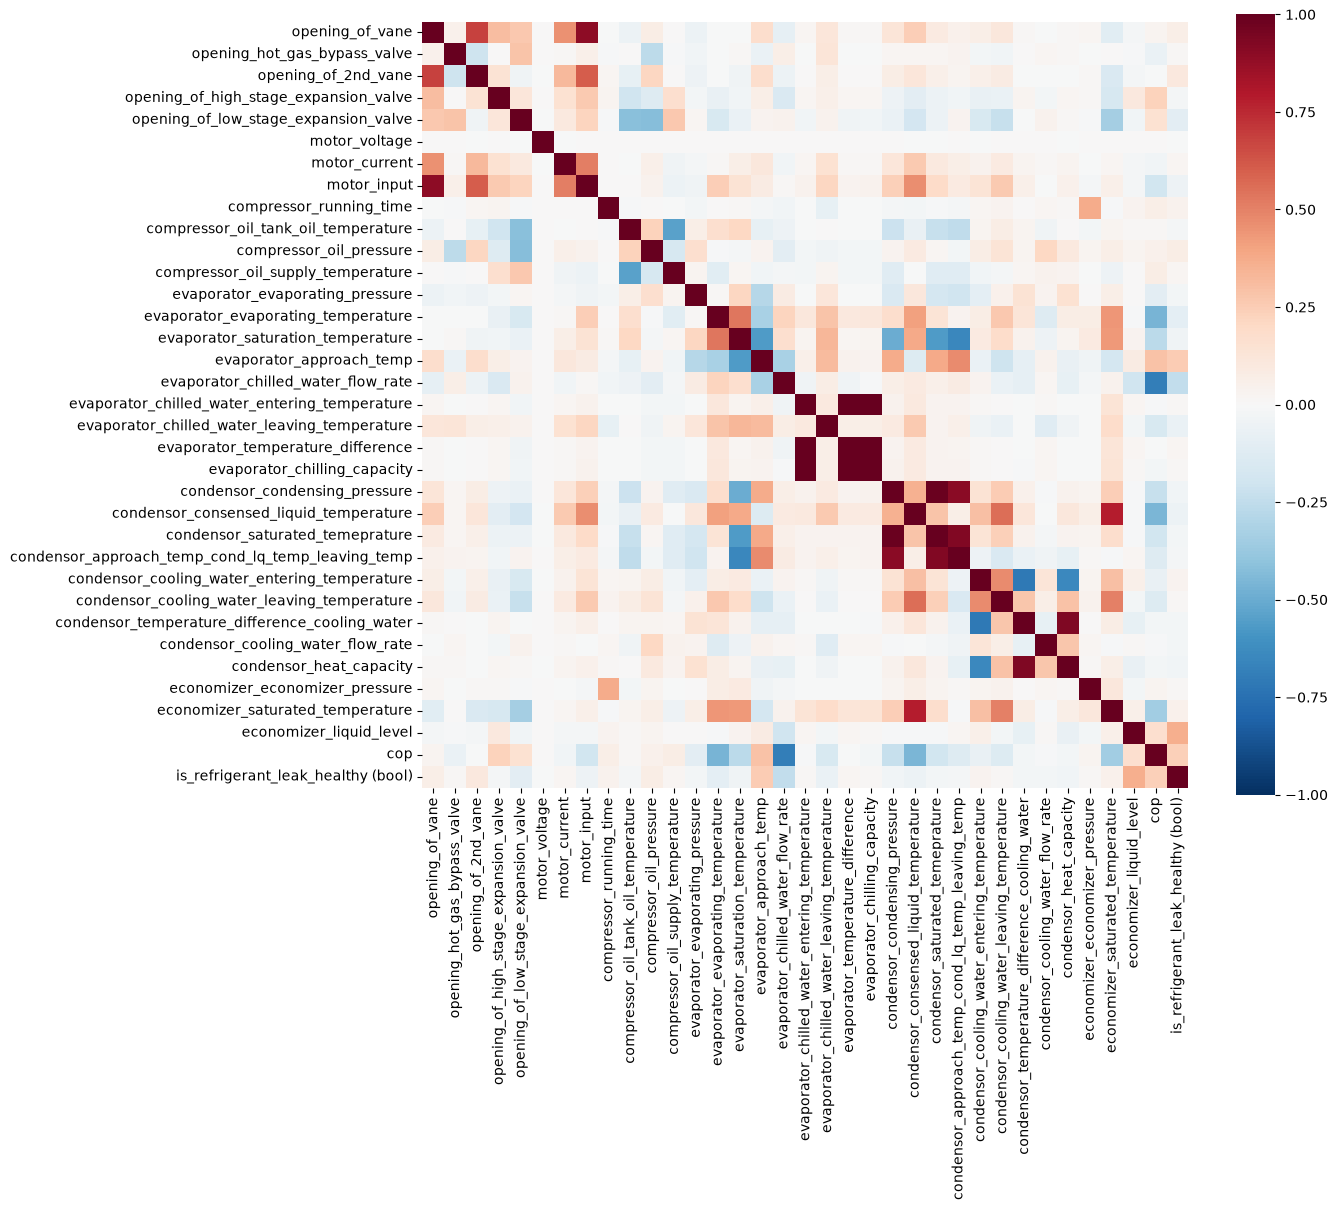

In [55]:
plt.figure(figsize=(14, 12))
sns.heatmap(corr.to_pandas(), xticklabels=sensor_cols, yticklabels=sensor_cols,
            cmap="RdBu_r", vmin=-1, vmax=1, annot=False, square=True)
plt.tight_layout()

Now we also take a look at the correlations of all units, however by their normalized values, to account for different baselines and operating settings for each chiller unit 

In [56]:
# Normalize values per chiller
z = df.drop_nulls().with_columns([
    ((pl.col(c) - pl.col(c).mean().over("chiller_id"))
        / pl.col(c).std().over("chiller_id")).alias(c)
    for c in sensor_cols
])
z_corr = z.select(sensor_cols).corr()

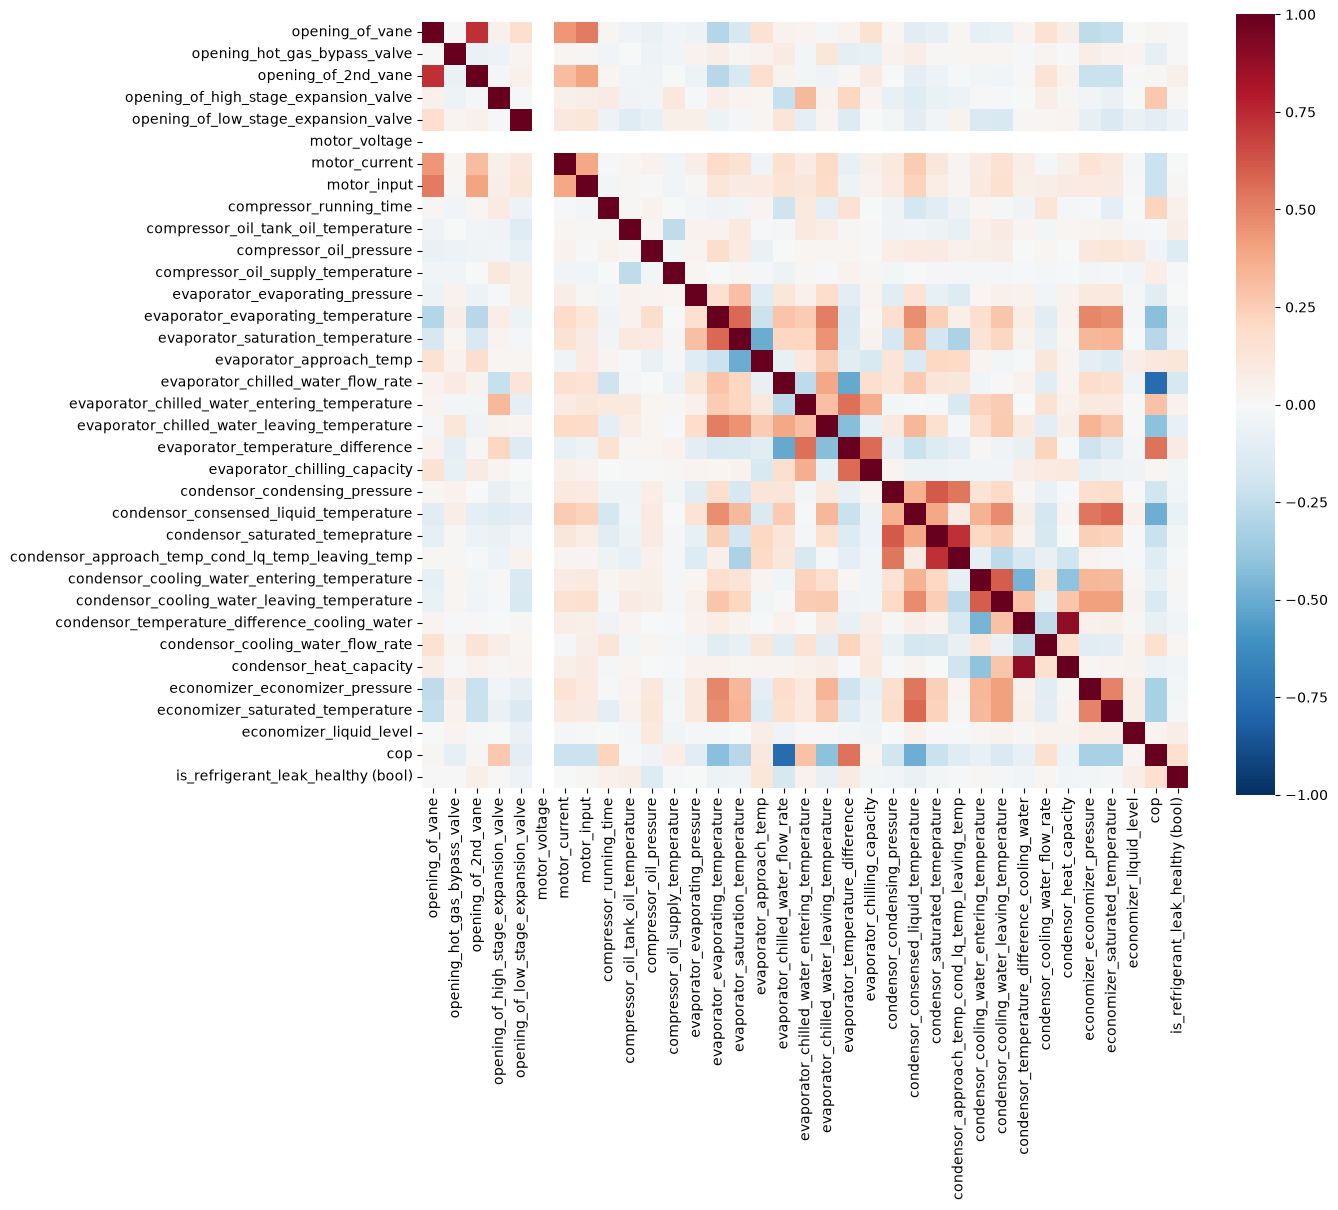

In [57]:
plt.figure(figsize=(14, 12))
sns.heatmap(z_corr.to_pandas(), xticklabels=sensor_cols, yticklabels=sensor_cols,
            cmap="RdBu_r", vmin=-1, vmax=1, annot=False, square=True)
plt.tight_layout()

Observation: motor voltage is a NaN, probably because it's constant

Let's see which sensors correlate the strongest:

In [58]:
z_corr_unpv = (
    z_corr
        .with_columns(pl.Series("sensor_a", sensor_cols))
        .unpivot(index="sensor_a", variable_name="sensor_b", value_name="corr")
        .filter(pl.col("sensor_a") != pl.col("sensor_b"))
        .filter(pl.col("sensor_a") > pl.col("sensor_b")) # deduplicate rows
        .drop_nans("corr")
        .with_columns(pl.col("corr").abs().alias("abs_corr"))
        .sort("abs_corr", descending=True)
)

with pl.Config(tbl_rows=45, tbl_cols=-1, fmt_str_lengths=100):
    display(z_corr_unpv)

sensor_a,sensor_b,corr,abs_corr
str,str,f64,f64
"""condensor_temperature_difference_cooling_water""","""condensor_heat_capacity""",0.884826,0.884826
"""evaporator_chilled_water_flow_rate""","""cop""",-0.771463,0.771463
"""opening_of_vane""","""opening_of_2nd_vane""",0.728562,0.728562
"""condensor_saturated_temeprature""","""condensor_approach_temp_cond_lq_temp_leaving_temp""",0.727495,0.727495
"""condensor_saturated_temeprature""","""condensor_condensing_pressure""",0.616808,0.616808
"""condensor_cooling_water_leaving_temperature""","""condensor_cooling_water_entering_temperature""",0.607422,0.607422
"""evaporator_saturation_temperature""","""evaporator_evaporating_temperature""",0.572518,0.572518
"""economizer_saturated_temperature""","""condensor_consensed_liquid_temperature""",0.572131,0.572131
"""evaporator_temperature_difference""","""evaporator_chilling_capacity""",0.567268,0.567268


Overall we can see that a few columns are strongly correlated, expecially when we look at the correlation diagrams of single units. This makes sense because they also sound like linear dependencies of each other e.g. in the case of evaporator temperatur difference and evaporator chilling capacity.

Otherwise though the columns seem highly independent. That's also why we are filling the remaining null values with their median for each column and chiller unit.

In [59]:
sensor_cols = [c for c in df.columns if c not in ("timestamp", "chiller_id")]

df = df.with_columns([
    pl.col(s).fill_null(pl.col(s).median().over("chiller_id")).alias(s)
    for s in sensor_cols
])

## Outliers

Next we will take a closer look at the outliers in the data set to check which might indicate an operating irregularity. We'll use Mean Absolute Deviation (MAD) and IQR for detecting outliers. 

In [60]:
ldf = df.unpivot(index=["timestamp", "chiller_id"], variable_name="sensor")

In [61]:
# Set selectivness of the IQR and MAD filter
mad_threshold = 4
iqr_threshold = 2

In [62]:
sensor_to_component = {
    sensor: component
    for component, cols in sensor_groups.items()
    for sensor in cols
}

ldf = ldf.with_columns(
    pl.col("sensor").replace(sensor_to_component).alias("component")
).drop_nulls()

In [63]:
# Calculate MAD for each unit, sensor pair

g = ["chiller_id", "sensor"]

outlier_ldf = (
    ldf.with_columns(median = pl.col("value").median().over(g))
    .with_columns(mad = (pl.col("value") - pl.col("median")).abs().median().over(g))
    .with_columns(rz = (pl.col("value") - pl.col("median")).abs() / (1.4826 * pl.col("mad")))
    .with_columns((pl.col("rz").is_not_nan() & (pl.col("mad") != 0) & (pl.col("rz") >= mad_threshold)).alias("mad_outlier"))
)

In [64]:
# Calculate IQR
outlier_ldf = (
    outlier_ldf.with_columns(
        q1 = pl.col("value").quantile(0.25).over(g),
        q3 = pl.col("value").quantile(0.75).over(g),
    ).with_columns(
        iqr = pl.col("q3") - pl.col("q1")
    ).with_columns(
        iqr_outlier = (pl.col("value") < pl.col("q1") - iqr_threshold * pl.col("iqr")) | (pl.col("value") > pl.col("q3") + iqr_threshold * pl.col("iqr"))
    )
)

In [65]:
combined_outlier_ldf = outlier_ldf.filter(pl.col("mad_outlier") & pl.col("iqr_outlier"))

In [66]:
combined_outlier_ldf

timestamp,chiller_id,sensor,value,component,median,mad,rz,mad_outlier,q1,q3,iqr,iqr_outlier
datetime[μs],str,str,f64,str,f64,f64,f64,bool,f64,f64,f64,bool
2024-08-17 09:00:00,"""C""","""opening_of_vane""",69.2,"""valves""",74.0,0.8,4.046945,true,72.9,74.7,1.8,true
2024-06-14 00:00:00,"""C""","""opening_of_vane""",36.6,"""valves""",74.0,0.8,31.532443,true,72.9,74.7,1.8,true
2024-08-25 09:00:00,"""C""","""opening_of_vane""",68.5,"""valves""",74.0,0.8,4.637124,true,72.9,74.7,1.8,true
2024-07-30 09:00:00,"""C""","""opening_of_vane""",63.4,"""valves""",74.0,0.8,8.937003,true,72.9,74.7,1.8,true
2024-06-13 09:00:00,"""C""","""opening_of_vane""",63.7,"""valves""",74.0,0.8,8.684069,true,72.9,74.7,1.8,true
2025-06-16 00:00:00,"""C""","""opening_of_vane""",68.5,"""valves""",74.0,0.8,4.637124,true,72.9,74.7,1.8,true
2024-06-25 00:00:00,"""C""","""opening_of_vane""",62.8,"""valves""",74.0,0.8,9.442871,true,72.9,74.7,1.8,true
2025-03-21 00:00:00,"""C""","""opening_of_vane""",65.0,"""valves""",74.0,0.8,7.588021,true,72.9,74.7,1.8,true
2024-08-20 09:00:00,"""C""","""opening_of_vane""",61.7,"""valves""",74.0,0.8,10.370295,true,72.9,74.7,1.8,true


### Typo Outliers

As mentioned before we assume that the dataset might contain outliers because of typos while noting values. For example motor voltage, a property that is mostly very constant and also should be constant from a domain knowledge pov, contains really strong outliers, that or off by powers of ten or look like they have a 0 inserted mistakenly for a point.

In this section we want to uncover those outliers and clean them.

The main strategy is to check
- how far out the IQR the value is (likely a typo)
- see if multiplying it by a power of ten brings the value close to the median again, as well as (likely a typo)
- checking if there are multiple outliers in the same data point (unlikely a typo)

In [202]:
# ---- tunable knobs -------------------------------------------------------
TOL_IQR_MULT      = 3   # closeness saturates to 0 once diff >= TOL_IQR_MULT * iqr
DEVIATION_WEIGHT    = 0.4   # weight for deviation_amount in the score
POT_WEIGHT     = 3.0   # weight for the "close to median after fix" signals
CROWD_PENALTY_WEIGHT = 1
# ---------------------------------------------------------------------

typo_ldf = combined_outlier_ldf.with_columns(
    (pl.col("mad_outlier") | pl.col("iqr_outlier")).alias("is_outlier")
)

# 1. how many outliers share this timestamp+chiller, or this timestamp+sensor
#    -> low count = isolated outlier = more typo-like
#       high count = whole system/sensor moved together = more likely a real event
typo_ldf = typo_ldf.with_columns([
    pl.col("is_outlier").sum().over(["timestamp", "chiller_id"]).alias("outlier_count_timestamp_chiller"),
    pl.col("is_outlier").sum().over(["timestamp", "sensor"]).alias("outlier_count_timestamp_sensor"),
])

# 2. amount of deviation - reuse the robust z-score you already computed
typo_ldf = typo_ldf.with_columns(
    pl.col("rz").abs().log1p().alias("deviation_amount")
)

# 3. power-of-ten checks: continuous closeness instead of a boolean
#    closeness = 1 when candidate lands exactly on median,
#    decays linearly to 0 once |candidate - median| >= TOL_IQR_MULT * iqr
def closeness_expr(factor: float) -> pl.Expr:
    candidate = pl.col("value") * factor
    tol = (TOL_IQR_MULT * pl.col("iqr").abs()).clip(lower_bound=1e-9)  # avoid div-by-zero
    diff = (candidate - pl.col("median")).abs()
    return (1.0 - (diff / tol)).clip(lower_bound=0.0, upper_bound=1.0)

power_factors = {"0.01": 0.01, "0.1": 0.1, "10": 10.0, "100": 100.0}

typo_ldf = typo_ldf.with_columns([
    closeness_expr(factor).alias(f"closeness_x{name}")
    for name, factor in power_factors.items()
])

# 4. combine into one score
closeness_cols = [f"closeness_x{name}" for name in power_factors]

typo_ldf = typo_ldf.with_columns(
    (
        - (pl.col("outlier_count_timestamp_chiller") + pl.col("outlier_count_timestamp_sensor") - 2).cast(pl.Int8).exp() * CROWD_PENALTY_WEIGHT
        + pl.sum_horizontal(closeness_cols) * POT_WEIGHT + pl.when(pl.col("deviation_amount") > 2 & (pl.sum_horizontal(closeness_cols) > 0)).then(1).otherwise(0)
        - ((pl.sum_horizontal([
            (pl.col(c) > 0).cast(pl.Int8)
            for c in closeness_cols
        ])).clip(lower_bound=1.0) - 1)
    ).alias("typo_likeliness")
)

typo_scored_ldf = typo_ldf.sort("typo_likeliness", descending=True)

/var/folders/v4/7l75g0h93gdfz9mx_0gyjh2m0000gn/T/ipykernel_2067/1011164635.py:44: DeprecationWarning: & on Unknown(Int(2)) and Boolean is deprecated and will raise a ComputeError in Polars 2.0
Hint: cast the Boolean to Int32 using pl.Expr.cast().
  typo_ldf = typo_ldf.with_columns(


In [203]:
x = typo_scored_ldf.select(
    "typo_likeliness",
    pl.exclude("typo_likeliness")
).drop("rz", "mad_outlier", "iqr", "iqr_outlier").head(40)

with pl.Config(tbl_rows=-1):
    display(x)

typo_likeliness,timestamp,chiller_id,sensor,value,component,median,mad,q1,q3,is_outlier,outlier_count_timestamp_chiller,outlier_count_timestamp_sensor,deviation_amount,closeness_x0.01,closeness_x0.1,closeness_x10,closeness_x100
f64,datetime[μs],str,str,f64,str,f64,f64,f64,f64,bool,u32,u32,f64,f64,f64,f64,f64
2.958315,2025-03-01 09:00:00,"""C""","""compressor_running_time""",482190.0,"""compressor""",48395.1,1455.9,44980.3,49204.8,true,1,1,5.308114,0.0,0.986105,0.0,0.0
2.946377,2025-03-08 09:00:00,"""F""","""economizer_liquid_level""",2000.8,"""economizer""",200.45,3.3,196.2,203.1,true,1,1,5.91073,0.0,0.982126,0.0,0.0
2.5,2025-03-19 09:00:00,"""E""","""condensor_condensing_pressure""",8.2,"""condensor""",0.81,0.01,0.8,0.82,true,1,1,6.213505,0.0,0.833333,0.0,0.0
2.39,2024-06-15 09:00:00,"""A""","""condensor_approach_temp_cond_l…",23.2,"""condensor""",2.2,0.4,1.7,2.5,true,1,1,3.594864,0.18,0.95,0.0,0.0
2.354456,2025-06-02 09:00:00,"""C""","""compressor_running_time""",4566.8,"""compressor""",48395.1,1455.9,44980.3,49204.8,true,1,1,3.058933,0.0,0.0,0.784819,0.0
2.0,2024-08-13 09:00:00,"""C""","""condensor_condensing_pressure""",81.0,"""condensor""",0.83,0.01,0.82,0.84,true,1,1,8.595707,0.666667,0.0,0.0,0.0
1.971429,2024-06-07 09:00:00,"""D""","""motor_input""",12.3,"""motor""",1194.0,15.0,1173.0,1208.0,true,1,1,3.991506,0.0,0.0,0.0,0.657143
1.264669,2025-05-25 09:00:00,"""D""","""condensor_cooling_water_flow_r…",129.1,"""condensor""",1291.52,7.68,1266.0,1296.5,true,2,1,4.63559,0.0,0.0,0.994317,0.0
0.9175,2024-06-05 09:00:00,"""C""","""evaporator_approach_temp""",-0.3,"""evaporator""",0.8,0.1,0.7,1.1,true,1,1,2.130538,0.330833,0.308333,0.0,0.0


#### Typo cleaning

In [204]:
typo_candidates_ldf = typo_scored_ldf.filter(pl.col("typo_likeliness") > 0)

closeness_cols = ["closeness_x0.01", "closeness_x0.1", "closeness_x10", "closeness_x100"]

typo_candidates_ldf = typo_candidates_ldf.with_columns(
    pl.max_horizontal(closeness_cols).alias("best_closeness_score")
)

# pick the factor whose closeness score is the max for that row
factor_expr = (
    pl.when(pl.col("closeness_x0.01") == pl.col("best_closeness_score")).then(0.01)
    .when(pl.col("closeness_x0.1") == pl.col("best_closeness_score")).then(0.1)
    .when(pl.col("closeness_x10") == pl.col("best_closeness_score")).then(10.0)
    .when(pl.col("closeness_x100") == pl.col("best_closeness_score")).then(100.0)
    .otherwise(1.0)  # no power-of-ten explains it -> factor 1 = "leave as-is"
)

typo_candidates_ldf = typo_candidates_ldf.with_columns(
    factor_expr.alias("correction_factor")
).with_columns(
    (pl.col("value") * pl.col("correction_factor")).alias("corrected_value")
)

print(typo_candidates_ldf.shape)

(10, 25)


In [205]:
corrections_ldf = typo_candidates_ldf.select("timestamp", "chiller_id", "sensor", "corrected_value")

corrections_df = corrections_ldf.pivot(
    values="corrected_value",
    index=["timestamp", "chiller_id"],
    on="sensor",  # use `columns="sensor"` on older Polars versions
)

# rename pivoted columns to avoid collision with originals
corrections_df = corrections_df.rename({
    c: f"{c}__corrected" for c in corrections_df.columns if c not in ("timestamp", "chiller_id")
})

cleaned_df = df.join(corrections_df, on=["timestamp", "chiller_id"], how="left")

sensor_cols = [c for c in df.columns if c not in ("timestamp", "chiller_id")]

cleaned_df = cleaned_df.with_columns([
    pl.coalesce([f"{s}__corrected", s]).alias(s)
    for s in sensor_cols if f"{s}__corrected" in cleaned_df.columns
]).drop([f"{s}__corrected" for s in sensor_cols if f"{s}__corrected" in cleaned_df.columns])

We conducted the Typo cleaning and found 28 outlier candidates that might be typos. In the face of the 720 outliers, however the effect of the cleaning is rather low. Also we still can't be entirely sure, if the outliers we classified as typos actually are typos or really just extreme outliers that happen to look like typos.

### Outlier Breakdown

In [206]:
# Dates with the most outliers
outlier_plt_df = combined_outlier_ldf.group_by((pl.col("timestamp").dt.date()).alias("date"), "chiller_id").len().sort("chiller_id")

fig = px.bar(outlier_plt_df, x="date", y="len", color="chiller_id", title="Outliers per day by chiller", height=600)
fig.update_xaxes(type="date", rangebreaks=[dict(bounds=["2024-09-01", "2025-02-27"])])

fig.show()

In [207]:
# Dates with the most outliers
outlier_plt_df = combined_outlier_ldf.group_by((pl.col("timestamp").dt.hour().cast(pl.Utf8) + ":00").alias("time"), "chiller_id").len().sort("time", "chiller_id")

fig = px.bar(outlier_plt_df, x="time", y="len", color="chiller_id", title="Outliers per hour by chiller", height=400)
fig.update_xaxes(type="category")

fig.show()

In [208]:
# Dates with the most outliers
outlier_plt_df = combined_outlier_ldf.group_by("chiller_id", "component").len().sort("chiller_id", "component")

fig = px.bar(outlier_plt_df, x="chiller_id", y="len", color="component", title="Outliers per chiller", height=400)
fig.update_xaxes(type="category")

fig.show()

In [209]:
# Dates with the most outliers
outlier_plt_df = (
    combined_outlier_ldf.group_by("component", "chiller_id")
    .len()
    .with_columns(pl.col("len").sum().over("component").alias("total_outliers"))
    .sort("chiller_id")
    .sort("total_outliers", descending=True)
)

fig = px.bar(outlier_plt_df, x="component", y="len", color="chiller_id", title="Outliers per component", height=400)
fig.update_xaxes(type="category")

fig.show()

In [210]:
daily_counts = combined_outlier_ldf.group_by("timestamp").len()
px.histogram(daily_counts, x="len").show()

display(daily_counts.sort("len", descending=True).head(10))

daily_counts = combined_outlier_ldf.group_by(pl.col("timestamp").dt.date()).len()
px.histogram(daily_counts, x="len").show()

display(daily_counts.sort("len", descending=True).head(10))

timestamp,len
datetime[μs],u32
2024-08-20 09:00:00,11
2024-06-13 09:00:00,9
2024-08-27 09:00:00,8
2024-06-24 09:00:00,6
2024-08-25 09:00:00,6
2024-07-14 09:00:00,5
2025-06-30 09:00:00,5
2024-06-16 09:00:00,4
2024-06-11 09:00:00,4


timestamp,len
date,u32
2024-08-20,11
2024-06-13,9
2024-08-27,8
2024-08-25,6
2024-06-24,6
2024-07-14,5
2025-06-30,5
2025-04-14,4
2025-04-24,4


In [211]:
with pl.Config(tbl_rows=60, tbl_cols=-1, fmt_str_lengths=100):
    display(
        combined_outlier_ldf
        .with_columns((pl.col("q1").cast(pl.Utf8) + " - " + pl.col("q3").cast(pl.Utf8)).alias("q1_q3_range"))
        .with_columns(
            pl.col("timestamp").len().over("timestamp").alias("outliers_per_day"),
        )
        .drop(["mad", "rz", "q1", "q3", "iqr", "mad_outlier", "iqr_outlier"])
        .sort(["outliers_per_day", "sensor", "chiller_id"], descending=[True, False, False])
        .head(60)
    )

timestamp,chiller_id,sensor,value,component,median,q1_q3_range,outliers_per_day
datetime[μs],str,str,f64,str,f64,str,u32
2024-08-20 09:00:00,"""A""","""economizer_liquid_level""",291.4,"""economizer""",200.3,"""194.2 - 206.6""",11
2024-08-20 09:00:00,"""C""","""evaporator_chilled_water_entering_temperature""",12.0,"""evaporator""",13.2,"""13.0 - 13.3""",11
2024-08-20 09:00:00,"""A""","""motor_current""",104.4,"""motor""",117.1,"""116.2 - 118.7""",11
2024-08-20 09:00:00,"""C""","""motor_current""",104.8,"""motor""",116.7,"""115.8 - 117.6""",11
2024-08-20 09:00:00,"""E""","""motor_current""",108.5,"""motor""",118.3,"""117.0 - 119.3""",11
2024-08-20 09:00:00,"""A""","""motor_input""",1027.0,"""motor""",1153.0,"""1144.0 - 1163.0""",11
2024-08-20 09:00:00,"""C""","""motor_input""",1074.0,"""motor""",1191.0,"""1180.0 - 1199.0""",11
2024-08-20 09:00:00,"""E""","""motor_input""",1101.0,"""motor""",1203.0,"""1191.0 - 1216.0""",11
2024-08-20 09:00:00,"""A""","""opening_of_2nd_vane""",55.0,"""valves""",67.3,"""65.7 - 68.7""",11


#### Observations
Process
- MAD isn't ideal for values that are very consistent and then only change strongly once
- Mixed with IQR it produces better results, but maybe it's still a bit noisy

Data
- There are a few dates with especially high numbers of outliers, such as 2024-06-11, 2024-06-13, 2025-04-27
- Components with the most outliers are condensor and compressor
- most outliers are recorded at midnight

## PCA
Next we're doing a pca on our sensor data to explore which measures have the most impact on variance

In [212]:
X_df = df.select(sensor_cols).drop_nulls()
X = X_df.to_numpy()

In [213]:
X_scaled = StandardScaler().fit_transform(X)
pca = PCA()
scores = pca.fit_transform(X_scaled)  

In [214]:
print("Variance captured by the PCs:")
print(pca.explained_variance_ratio_)

print("\nCumulative variance captured by the PCs:")
print(np.cumsum(pca.explained_variance_ratio_))

Variance captured by the PCs:
[1.17196213e-01 1.11278896e-01 8.52281873e-02 7.18946682e-02
 6.34960487e-02 5.41788513e-02 3.76074608e-02 3.47220226e-02
 3.17186554e-02 2.93470909e-02 2.88773657e-02 2.88067178e-02
 2.82728368e-02 2.78829717e-02 2.68583255e-02 2.50303568e-02
 2.33621693e-02 2.27515065e-02 2.12990782e-02 2.04332781e-02
 1.84103189e-02 1.80758922e-02 1.51049509e-02 1.45074287e-02
 1.03314563e-02 9.73379846e-03 8.28949861e-03 5.73369404e-03
 3.96429202e-03 3.26837652e-03 1.66123230e-03 6.71695249e-04
 4.51319088e-06 1.44002013e-07 7.56031289e-09]

Cumulative variance captured by the PCs:
[0.11719621 0.22847511 0.3137033  0.38559797 0.44909401 0.50327287
 0.54088033 0.57560235 0.607321   0.63666809 0.66554546 0.69435218
 0.72262502 0.75050799 0.77736631 0.80239667 0.82575884 0.84851034
 0.86980942 0.8902427  0.90865302 0.92672891 0.94183386 0.95634129
 0.96667275 0.97640655 0.98469605 0.99042974 0.99439403 0.99766241
 0.99932364 0.99999534 0.99999985 0.99999999 1.        ]


#### Observations
- There are quite many modes to the data
- However there are also a few dependencies between the measurements: The last 14 PCs only carry about 10% of the variance

In [215]:
n_pcs = 10
scores_df = pl.DataFrame(scores[:, :n_pcs], schema=[f"PC{x+1}" for x in range(n_pcs)])

loadings = (
    pl.DataFrame(pca.components_[:n_pcs].T, schema=[f"PC{x+1}" for x in range(n_pcs)])
    .with_columns(pl.Series("sensor", sensor_cols))
)

In [216]:
pc = "PC7"

with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=100):
    display(
        loadings
        .select("sensor", pc)
        .with_columns(contribution = pl.col(pc) ** 2)
        .sort("contribution", descending=True)
        .with_columns(cumulative = pl.col("contribution").cum_sum())
    )

sensor,PC7,contribution,cumulative
str,f64,f64,f64
"""opening_hot_gas_bypass_valve""",0.501726,0.251729,0.251729
"""compressor_oil_tank_oil_temperature""",0.377173,0.142259,0.393988
"""compressor_oil_supply_temperature""",-0.358261,0.128351,0.52234
"""is_refrigerant_leak_healthy (bool)""",0.33978,0.11545,0.63779
"""condensor_cooling_water_entering_temperature""",0.289606,0.083872,0.721662
"""evaporator_evaporating_pressure""",0.247398,0.061206,0.782868
"""opening_of_low_stage_expansion_valve""",0.209206,0.043767,0.826635
"""evaporator_evaporating_temperature""",-0.188228,0.03543,0.862065
"""condensor_approach_temp_cond_lq_temp_leaving_temp""",-0.154779,0.023957,0.886021


In [217]:
# sort rows by sensor name, then split labels from the numeric matrix
loadings_sorted = loadings.sort("sensor")

pc_names = [f"PC{i+1}" for i in range(n_pcs)]
L = loadings_sorted.select(pc_names).to_numpy()      # numeric only, for the image
y_sensors = loadings_sorted["sensor"].to_list()      # labels, in the sorted order

zmax = abs(L).max()

fig = px.imshow(
    L,
    x=pc_names,
    y=y_sensors,
    color_continuous_scale="RdBu_r", zmin=-zmax, zmax=zmax,
    aspect="auto", height=900,
    title="PCA loadings",
)
fig.show()

#### Observation
- PC1 is strongly associated with evaporator chilling capacity
- PC4 is strongly associated with condensor water temperatures
- PC7 is strongly associated with economizer pressure and compressor running time